```markdown
# Projeto: Classificação de Notícias por Assunto
**Disciplina:** Aprendizagem de Maquina  
**Professor(a):** Bruno Zolotareff  
**Integrantes:** Luan Oliveira Andrade  
**Ambiente:** Google Colab  
**Linguagem:** Python

---

## A. Resumo da Proposta
Este projeto apresenta o desenvolvimento de um Classificador de Notícias automatizado utilizando técnicas introdutórias de Processamento de Linguagem Natural (PLN) e Aprendizado de Máquina Supervisionado. A proposta visa criar um modelo capaz de analisar o título e o corpo (descrição) de uma notícia em inglês e categorizá-la automaticamente em uma de quatro classes: *World* (Mundo), *Sports* (Esportes), *Business* (Negócios) ou *Sci/Tech* (Ciência/Tecnologia).

## B. Objetivo e Problema
Com o volume massivo de informações geradas diariamente, a triagem manual de notícias torna-se inviável. O problema consiste em identificar o assunto de um texto jornalístico de forma rápida e sistemática. O objetivo deste projeto é construir e avaliar um Produto Mínimo Viável (MVP) de classificação de texto, servindo como base didática para estudantes de Aprendizado de Máquina.

## C. Solução Prévia
A solução adotada segue um pipeline clássico de Processamento de Linguagem Natural:
1. **Fusão de Atributos:** União do título (*title*) com a descrição (*description*) para fornecer mais contexto ao modelo.
2. **Vetorização (TF-IDF):** Conversão do texto estruturado em representações numéricas baseadas na importância estatística das palavras.
3. **Classificação (Naive Bayes Multinomial):** Algoritmo probabilístico ideal para contagem de frequências em textos, conhecido por sua eficiência e simplicidade.
4. **Predição de Novas Entradas:** Interface simples para o usuário submeter um texto e obter a classificação predita em tempo real.

## D. Dados e Algoritmo do MVP
* **Base de Dados:** AG News (utilizando os DataFrames `treino` e `teste` já presentes no ambiente).
* **Categorias:** 1 - World, 2 - Sports, 3 - Business, 4 - Sci/Tech.
* **Algoritmos:** `TfidfVectorizer` e `MultinomialNB` da biblioteca `scikit-learn`.
* **Divisão de dados:** Utilização estrita dos conjuntos separados de fábrica para evitar vazamento de dados (*data leakage*).



In [6]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


```markdown
### Passo 1: Verificação e Preparação dos Dados
Vamos verificar a estrutura dos DataFrames `treino` e `teste` já carregados na memória do Colab. Mapearemos as classes numéricas para seus nomes originais correspondentes no AG News.
```

In [7]:
# Dicionário de mapeamento original das classes do AG News
# Nota: Os rótulos na base AG News costumam ser 1, 2, 3, 4.
# Vamos mapear dinamicamente para os nomes legíveis.
mapeamento_categorias = {
    1: 'World',
    2: 'Sports',
    3: 'Business',
    4: 'Sci/Tech'
}

print("Amostra dos Dados de Treino:")
display(treino.head())

print("\nAmostra dos Dados de Teste:")
display(teste.head())

Amostra dos Dados de Treino:


,label,title,description
0,3,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli..."
1,3,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...
2,3,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...
3,3,Iraq Halts Oil Exports from Main Southern Pipe...,Reuters - Authorities have halted oil export\f...
4,3,"Oil prices soar to all-time record, posing new...","AFP - Tearaway world oil prices, toppling reco..."



Amostra dos Dados de Teste:


,label,title,description
0,3,Fears for T N pension after talks,Unions representing workers at Turner Newall...
1,4,The Race is On: Second Private Team Sets Launc...,"SPACE.com - TORONTO, Canada -- A second\team o..."
2,4,Ky. Company Wins Grant to Study Peptides (AP),AP - A company founded by a chemistry research...
3,4,Prediction Unit Helps Forecast Wildfires (AP),AP - It's barely dawn when Mike Fitzpatrick st...
4,4,Calif. Aims to Limit Farm-Related Smog (AP),AP - Southern California's smog-fighting agenc...


```markdown
### Passo 2: Criação da Feature Combinada (Texto Completo)
Para melhorar o contexto fornecido ao classificador, vamos combinar o Título (`title`) e a Descrição (`description`) em um único atributo de texto para ambos os conjuntos.
```

In [8]:
# Tratamento de valores nulos se houverem
treino = treino.fillna('')
teste = teste.fillna('')

# Combinação de título e descrição
treino['texto_completo'] = treino['title'] + " " + treino['description']
teste['texto_completo'] = teste['title'] + " " + teste['description']

# Definição das variáveis de entrada e saída
X_train = treino['texto_completo']
y_train = treino['label']

X_test = teste['texto_completo']
y_test = teste['label']

print(f"Quantidade de registros para treino: {len(X_train)}")
print(f"Quantidade de registros para teste: {len(X_test)}")

Quantidade de registros para treino: 120000
Quantidade de registros para teste: 7600


```markdown
### Passo 3: Vetorização com TF-IDF e Treino do Modelo Naive Bayes
Nesta etapa, criamos o vetorizador TF-IDF limitando palavras irrelevantes em inglês (stopwords) e aplicamos o fit apenas nos dados de treino para evitar vazamento de dados (*data leakage*).
```

In [9]:
# Inicializa o vetorizador TF-IDF com remoção de stop words em inglês
vectorizer = TfidfVectorizer(stop_words='english', max_features=10000)

# Ajusta e transforma os dados de treino
X_train_tfidf = vectorizer.fit_transform(X_train)

# Apenas transforma os dados de teste (sem ajustar o vocabulário novamente)
X_test_tfidf = vectorizer.transform(X_test)

# Instancia o classificador Naive Bayes Multinomial
modelo = MultinomialNB()

# Treina o classificador
modelo.fit(X_train_tfidf, y_train)

print("Modelo TF-IDF + Naive Bayes Multinomial treinado com sucesso!")

Modelo TF-IDF + Naive Bayes Multinomial treinado com sucesso!


```markdown
### Passo 4: Avaliação de Desempenho do Modelo
Agora que o modelo foi treinado, faremos as predições no conjunto de teste e exibiremos as métricas de performance.
```

Acurácia obtida: 0.8967

Relatório de Classificação:
              precision    recall  f1-score   support

       World       0.91      0.89      0.90      1900
      Sports       0.95      0.98      0.96      1900
    Business       0.87      0.85      0.86      1900
    Sci/Tech       0.87      0.87      0.87      1900

    accuracy                           0.90      7600
   macro avg       0.90      0.90      0.90      7600
weighted avg       0.90      0.90      0.90      7600



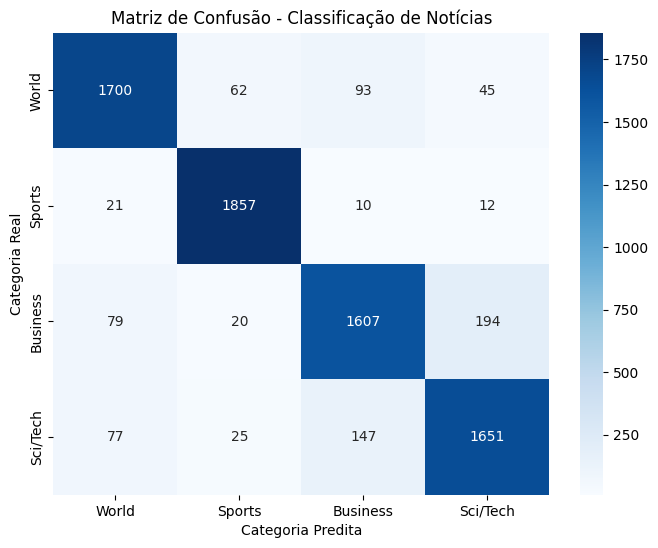

In [10]:
# Predições
y_pred = modelo.predict(X_test_tfidf)

# Mapeamento dos rótulos para exibição correta dos relatórios
labels_unicos = sorted(list(set(y_test)))
target_names = [mapeamento_categorias.get(l, f"Classe {l}") for l in labels_unicos]

# Métricas gerais
acuracia = accuracy_score(y_test, y_pred)
print(f"Acurácia obtida: {acuracia:.4f}\n")

print("Relatório de Classificação:")
print(classification_report(y_test, y_pred, target_names=target_names))

# Matriz de Confusão
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_names, yticklabels=target_names)
plt.title('Matriz de Confusão - Classificação de Notícias')
plt.ylabel('Categoria Real')
plt.xlabel('Categoria Predita')
plt.show()

```markdown
### Passo 5: Interface de Teste em Tempo Real
Utilize o campo de texto abaixo para simular a classificação de uma notícia qualquer em inglês e conferir a classe predita pelo modelo.
```

In [11]:
def classificar_noticia(titulo, descricao):
    texto_combinado = titulo + " " + descricao
    vetorizado = vectorizer.transform([texto_combinado])
    classe_id = modelo.predict(vetorizado)[0]
    categoria = mapeamento_categorias.get(classe_id, f"Classe {classe_id}")
    return categoria

# EXEMPLO DE TESTE (Altere os valores abaixo para testar novas notícias)
titulo_exemplo = "NASA James Webb telescope captures stunning new images of distant galaxies"
descricao_exemplo = "The space agency revealed high-resolution infrared photographs showing unprecedented cosmic details."

resultado = classificar_noticia(titulo_exemplo, descricao_exemplo)
print(f"Título: {titulo_exemplo}")
print(f"Descrição: {descricao_exemplo}")
print(f"Categoria Predita pelo Modelo: {resultado}")

Título: NASA James Webb telescope captures stunning new images of distant galaxies
Descrição: The space agency revealed high-resolution infrared photographs showing unprecedented cosmic details.
Categoria Predita pelo Modelo: Sci/Tech


```markdown
---

## G. Referências

1. **Pedregosa, F. et al.** (2011). *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research, 12, pp. 2825-2830. Disponível em: [https://jmlr.org/papers/v12/pedregosa11a.html](https://jmlr.org/papers/v12/pedregosa11a.html)
2. **Manning, C. D., Raghavan, P., & Schütze, H.** (2008). *Introduction to Information Retrieval* (Capítulo 6 - TF-IDF e similaridade vetorial). Cambridge University Press. Disponível em: [https://nlp.stanford.edu/IR-book/](https://nlp.stanford.edu/IR-book/)
3. **Zhang, X., Zhao, J., & LeCun, Y.** (2015). *Character-level Convolutional Networks for Text Classification* (Artigo que formalizou e popularizou o uso moderno do dataset AG News). arXiv preprint arXiv:1509.01626. Disponível em: [https://arxiv.org/abs/1509.01626](https://arxiv.org/abs/1509.01626)

